In [44]:
### 텐서플로우 프레임 워크
import tensorflow as tf

### 딥러닝 관련 라이브러리(모델 포함)
from tensorflow import keras

import numpy as np

from sklearn .model_selection import train_test_split

### 사용할 라이브러리 불러들이기
# 데이터 조작을 위한 라이브러리

import pandas as pd

# 기본 시각화 라이브러리

import matplotlib.pyplot as plt

# 통계적 시각화 라이브러리(보통 기본 시각화보다 향상된 라이브러리라고 생각하면 됨)

import seaborn as sns

# 시각화 시 그래프의 너비/높이를 기본 설정하기

plt.rcParams["figure.figsize"] = (12, 5)

# 시각화시 한글 깨짐 처리를 위한 폰트 지정 (Window OS 기준)- 항상

#plt.rcParams["font.family"] = "Malgun Gothic"


# 시각화시 마이너스 (-) 기호 깨짐 방지 처리-항상

#plt.rcParams["axes.unicode_minus"] =False


# - 딥러닝 랜덤 규칙 정의
#  -> 딥러닝은 내부적으로 데이터를 랜덤하게 선별하여 훈련에 적용하고 패턴을 찾아내기에
#  -> 랜덤 규칙을 적용하더라도 일정한 값을 얻기 힘듬(훈련 반복시 조금씩 결과값 차이 있음)
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()




In [2]:
"""
1. 사용 데이터 : fashion_mnist
2. 데이터 불러들이기
3. 데이터 스케일링
4. 훈련:검증 = 8:2로 분리하기

** 변수는 어제 사용한 변수명으로...
"""

'\n1. 사용 데이터 : fashion_mnist\n2. 데이터 불러들이기\n3. 데이터 스케일링\n4. 훈련:검증 = 8:2로 분리하기\n\n** 변수는 어제 사용한 변수명으로...\n'

In [29]:
(train_input, train_target), (test_input, test_target) = (
    keras.datasets.fashion_mnist.load_data()
)

# 3. 데이터 스케일링 (0~255 → 0~1)
train_scaled_255 = train_input / 255.0
test_scaled_255 = test_input / 255.0

train_scaled_2, val_scaled, train_target, val_target = train_test_split(
    train_scaled_255,
    train_target,
    test_size=0.2,
    random_state=42
)

print("훈련:", train_scaled_2.shape, train_target.shape)
print("테스트:",test_scaled_255.shape,test_target.shape)
print("검증:", val_scaled.shape, val_target.shape)



훈련: (48000, 28, 28) (48000,)
테스트: (10000, 28, 28) (10000,)
검증: (12000, 28, 28) (12000,)


### DNN(Deep Neutral Network : 심층 신경망)

In [4]:
### DNN
# - 은닉계층(Hidden Layer)이 있는 경우를 의미함
# - 계층 3개 이상인 경우를 의미함
# - 입력계층(여러개 들어갈 수 도 있다) + 은닉계층(여러개 가능) + ... + n개 + 출력계층(종속변수의 범주값을 찾기위한것)

### 은닉계층을 생성하는 함수 생성

In [5]:
"""
<아래와 같은 함수 정의하기>
 - 함수 이름 : model_fn(add_layer)
 - 매개변수명 : add_layer(은닉계층이 0개 또는 1개 이상 포함된 리스트 타입)
             :  add_layer의 디폴트값(기본값)은 None으로 정의
             :  값을 받을 경우에는 리스트[] 타입으로 받기

 - 은닉계층은 add_layer 변수가 받아서 model에 추가
   -> 예시 : [은닉계층1, 은닉계층2...]
 
 - 함수 내에서 아래와 같이 처리
   1. 모델 생성
   2. 입력계층은 (자원축소 전처리 계층사용) 생성 및 모델에 추가 
   3. 은닉계층은 add_layer가 받아온 계층 리스트가 입력 계층 생성(차원축소 전처리 계층 사용) 및 모델에 추가있으면
       -> 리스트 내에 있는 계층들을 모델에 순서대로 추가
   4. 출력 계층 생성 및 모델에 추가
   5. 모델 반환
"""

'\n<아래와 같은 함수 정의하기>\n - 함수 이름 : model_fn(add_layer)\n - 매개변수명 : add_layer(은닉계층이 0개 또는 1개 이상 포함된 리스트 타입)\n             :  add_layer의 디폴트값(기본값)은 None으로 정의\n             :  값을 받을 경우에는 리스트[] 타입으로 받기\n\n - 은닉계층은 add_layer 변수가 받아서 model에 추가\n   -> 예시 : [은닉계층1, 은닉계층2...]\n \n - 함수 내에서 아래와 같이 처리\n   1. 모델 생성\n   2. 입력계층은 (자원축소 전처리 계층사용) 생성 및 모델에 추가 \n   3. 은닉계층은 add_layer가 받아온 계층 리스트가 입력 계층 생성(차원축소 전처리 계층 사용) 및 모델에 추가있으면\n       -> 리스트 내에 있는 계층들을 모델에 순서대로 추가\n   4. 출력 계층 생성 및 모델에 추가\n   5. 모델 반환\n'

In [6]:
def model_fn(add_layer=None):

    #모델생성
    model = keras.Sequential()
    # 차원축소 
    model.add(keras.layers.Flatten(input_shape=(28, 28)))

    # 은닉계층: 전달받은 은닉 계층이 있다면 (처리 없으면 처리 안함)
    if add_layer is not None:
        # 리스트 타입으로 전달 받은 은닉계층(add-layer)이 있다면
        for layer in add_layer:
            model.add(layer)

    # 출력계층에 추가 
    model.add(keras.layers.Dense(10, activation="softmax"))

    return model


In [7]:
### 은닉 계층 없이 모델 생성하기(함수 호출)
model_temp = model_fn()
model_temp.summary()

/home/server/workspace/02_Deep_Learning_TensorFlow/.venv/lib/python3.10/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
W0000 00:00:1793242652.700010   72640 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1793242652.703311   72640 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1793242652.832873   72640 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5219 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060, pci bu

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
### 은닉 계층이 있는 모델 생성하기(함수 호출)
hidden_layer = keras.layers.Dense(units=100, activation="relu")


model_temp = model_fn([hidden_layer])
model_temp.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

### 훈련에 사용할 모델 생성

In [31]:
### 은닉계층 1개 추가
# - 출력 갯수 64, 활성화 함수 relu
# - 은닉층 변수명 : model1

### 은닉계층 2개 추가
# - 첫 번째 은닉층 : 출력 갯수 100, 활성화 함수 relu
# - 두 번째 은닉층 : 출력 갯수 64, 활성화 함수 relu

### 은닉 계층이 있는 모델 생성하기(함수 호출)
hidden_layer1 = keras.layers.Dense(units=100, activation="relu")
hidden_layer2 = keras.layers.Dense(units=64, activation="relu")

model_temp = model_fn([hidden_layer1, hidden_layer2])
model_temp.summary()


### 모델 환경 설정 : 손실과 출력결과만 작성
model_temp.compile(
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


### 훈련 5회 시키기
history = model_temp.fit(
    train_scaled_2,
    train_target,
    epochs=5,
    verbose=2
)

### 훈련결과 받아오기
history

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_12 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 64)             │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,614 (334.43 KB)

 Trainable params: 85,614 (334.43 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5


I0000 00:00:1793243708.948903   72765 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_214722__.13


1500/1500 - 3s - 2ms/step - accuracy: 0.8095 - loss: 0.5321
Epoch 2/5
1500/1500 - 2s - 2ms/step - accuracy: 0.8586 - loss: 0.3899
Epoch 3/5
1500/1500 - 2s - 1ms/step - accuracy: 0.8727 - loss: 0.3546
Epoch 4/5
1500/1500 - 2s - 2ms/step - accuracy: 0.8797 - loss: 0.3363
Epoch 5/5
1500/1500 - 2s - 2ms/step - accuracy: 0.8849 - loss: 0.3235


In [32]:
### History 클래스 안에는 훈련 (fit)결과가 저장되어 있음
# 반복 횟수(epoch) 값 추출
print(history.epoch)

# 훈련 반복 마다 발생한 정확도와 손실율 결과값 추출 : 반환 타입은 딕셔너리 (dict)
print(history.history)

[0, 1, 2, 3, 4]
{'accuracy': [0.809541642665863, 0.8586458563804626, 0.8726875185966492, 0.8796666860580444, 0.8849375247955322], 'loss': [0.532055139541626, 0.3898966908454895, 0.35462304949760437, 0.33625975251197815, 0.3235274851322174]}


### 손실곡선 시각화

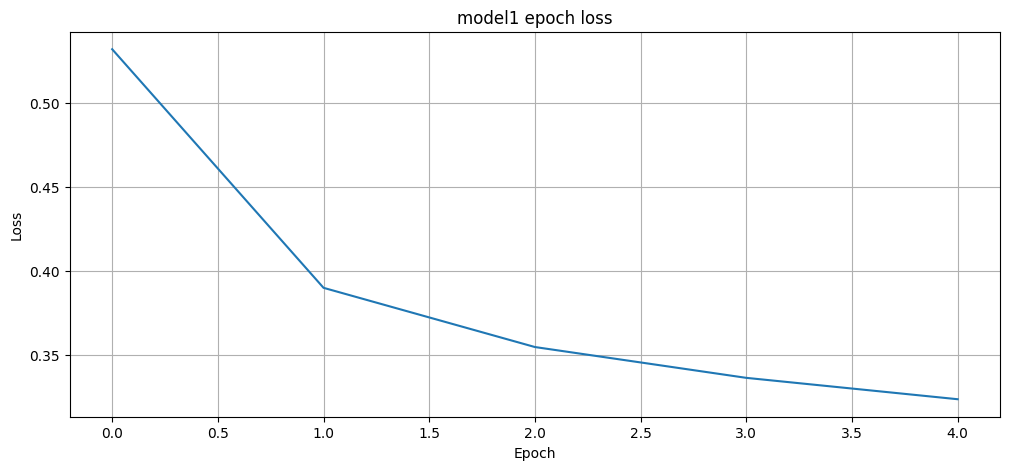

In [33]:
### 훈련 반복에 따른 손실율(loss) 추이 시각화
# - 그래프 종류: 선그래프
# - x축:반복 횟수
# - y축:손실율

plt.title("model1 epoch loss")
plt.plot(history.epoch, history.history["loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()

### 그래프 이미지로 저장하기 (show를 먼저하면 그래프 내용이 저장되지 않음)
plt.savefig("./saveFig/model1_epoch_loss_01.png")

plt.show()

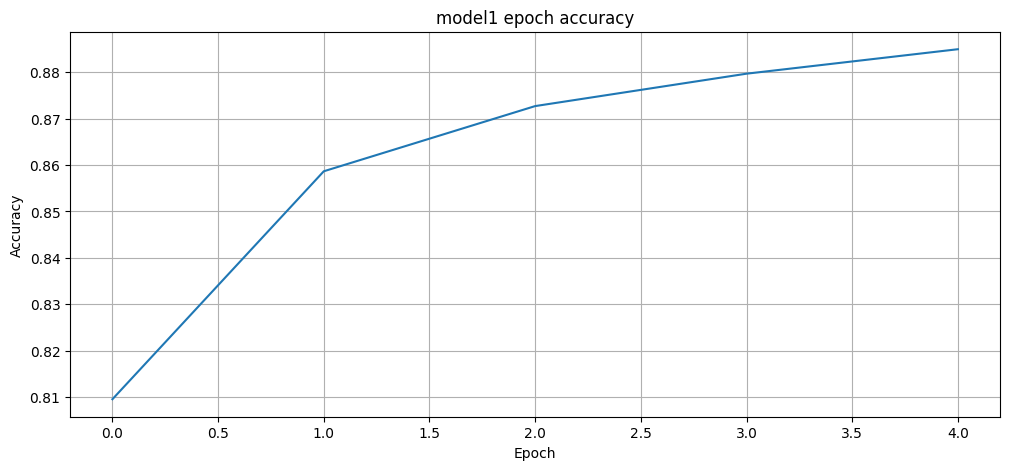

In [34]:
### 훈련 반복에 따른 정확도(accuracy) 추이 시각화
# - 그래프 종류 : 선그래프(plot())
# - x축 : 반복횟수
# - y축 : 정확도
# - 이미지 파일로 저장 :model1_epoch_accuracy_01.png

plt.title("model1 epoch accuracy")
plt.plot(history.epoch, history.history["accuracy"])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid()
plt.savefig("./saveFig/model1_epoch_accuracy_01.png")
plt.show()


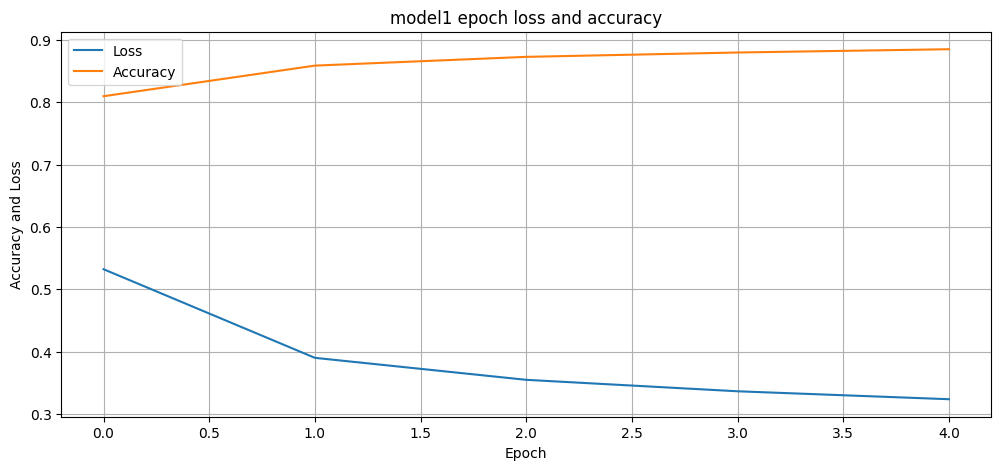

In [ ]:
### 훈련 반복에 따른 손실율(loss)과 정확도(accuracy) 추이 시각화
# - 그래프 종류 : 선그래프(plot())
# - x축 : 반복횟수
# - y축 : 손실율 and 정확도
# - 이미지 파일로 저장 : model1_epoch_loss_accuracy_01.png

plt.title("model1 epoch loss and accuracy")

# 손실률 그래프
plt.plot(history.epoch, history.history["loss"], label="Loss")

# 정확도 그래프
plt.plot(history.epoch, history.history["accuracy"], label="Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy and Loss")
plt.legend()
plt.grid()

### 그래프 이미지로 저장하기

plt.savefig("./saveFig/model1_epoch_loss_accuracy_01.png")

plt.show()


### 훈련 (fit)시에 검증 데이터를 포함하여 훈련시키기

In [36]:
### 은닉계층 출력갯수 100개, 활성화함수 relu로 모델 생성하기
# 모델 구조 확인하기

h_layer = keras.layers.Dense(units=100, activation="relu")
model = model_fn([h_layer])
model.summary()

model.compile(
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### 훈련시 훈련데이터와 검증데이터 모두 사용해서 훈련시키기
# - validation_data : 검증 데이터 추가 속성 변수
#                   : 훈련 중 검증에 대한 정확도와 손실율을 포함하여 출력됨
history = model.fit(train_scaled_2, train_target, epochs=50,
                    validation_data=(val_scaled, val_target))


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_13 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50


I0000 00:00:1793243731.833882   72761 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_245477__.12


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8143 - loss: 0.5316 - val_accuracy: 0.8516 - val_loss: 0.4142
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8593 - loss: 0.3905 - val_accuracy: 0.8655 - val_loss: 0.3701
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8723 - loss: 0.3525 - val_accuracy: 0.8715 - val_loss: 0.3745
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8806 - loss: 0.3335 - val_accuracy: 0.8798 - val_loss: 0.3601
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8872 - loss: 0.3156 - val_accuracy: 0.8823 - val_loss: 0.3446
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8917 - loss: 0.3041 - val_accuracy: 0.8769 - val_loss: 0.3552
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8954 - loss: 0.2935 - val_accuracy: 0.8794 - val_loss: 0.3574
Epoch 8/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8986 - loss: 0.2853 - val_accurac

In [37]:
print(history.epoch)
print(history.history.keys())

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49]
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


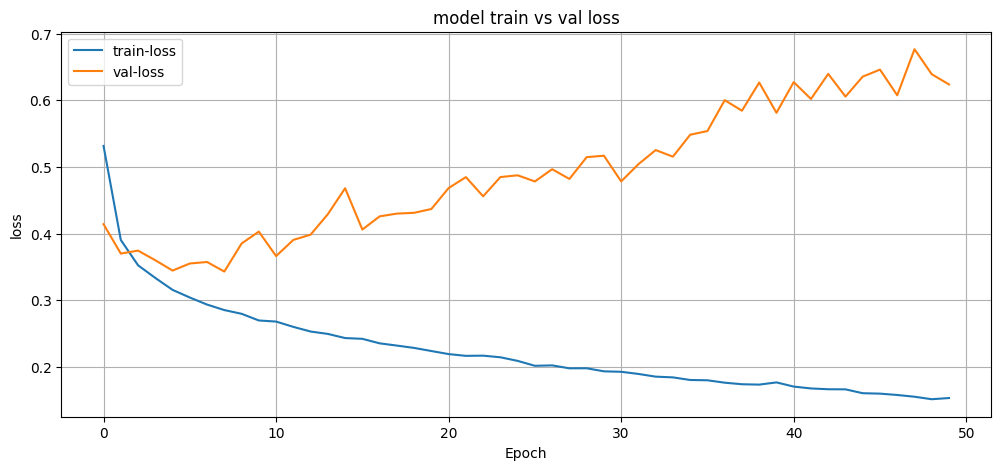

In [ ]:
### 훈련 횟수에 따른 훈련 vs 검증에 대한 손실율(loss) 비교 시각화
# - 훈련 손실율과 검증 손실율 곡선을 하나의 그래프에 선그래프로 그려주세요.

plt.title("model train vs val loss")
plt.plot(history.epoch, history.history["loss"])
plt.plot(history.epoch, history.history["val_loss"])

plt.xlabel("Epoch")
plt.ylabel("loss")
plt.grid()

### 범례표시
plt.legend(["train-loss","val-loss"])

plt.show()

"""
(해석)
- 최초에는 과속적합 (훈련손실이 매우 큼 )이 발생하였으며,
이후 과소적합은 해소가 됨
- 초반 이후부터는 지속적으로 과대적합이 발생하고 있음
- 따라서, 훈련횟수를 더이상 눌리는 것은 타당하지 않음
"""



Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_22 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8163 - loss: 0.5255 - val_accuracy: 0.8407 - val_loss: 0.4409
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8595 - loss: 0.3951 - val_accuracy: 0.8533 - val_loss: 0.4023
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8726 - loss: 0.3531 - val_accuracy: 0.8583 - val_loss: 0.3834
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8813 - loss: 0.3256 - val_accuracy: 0.8661 - val_loss: 0.3593
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8888 - loss: 0.3049 - val_accuracy: 0.8688 - val_loss: 0.3593
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8949 - loss: 0.2890 - val_accuracy: 0.8712 - val_loss: 0.3582
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8996 - loss: 0.2746 - val_accuracy: 0.8727 - val_loss: 0.3538
Epoch 8/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9032 - loss: 0.2630 - 

Text(0.5, 0, 'Epoch')

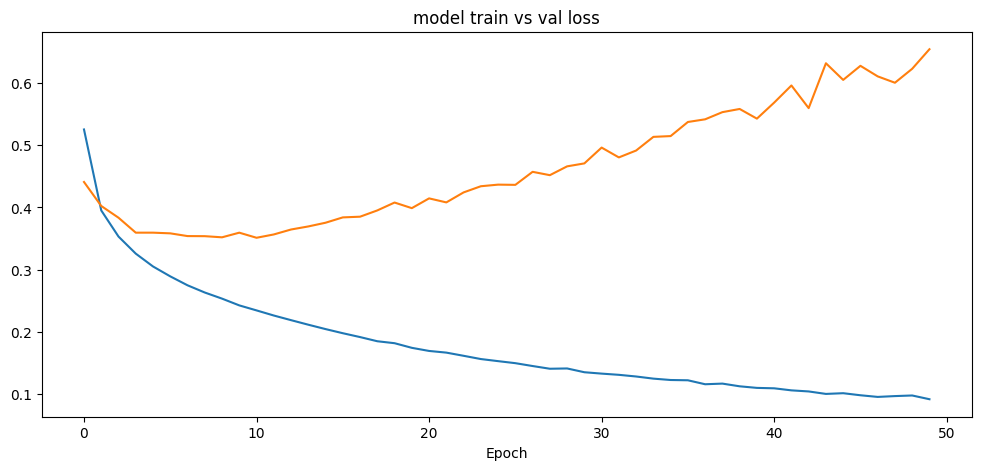

In [ ]:
"""
<신규모델 생성>
 - 옵티마이저 : adam
 - 학습율 : 0.1
 - 은닉계층 : 출력갯수 100개,
 - 훈련횟수 : 50회
 - 훈련 및 검증 데이터 모두 사용하여 훈련 시키기
 - 훈련 vs 검증 손실곡선 시각화
"""
# 모델생성
model = keras.Sequential()

# 입력층
model.add(keras.layers.Flatten(input_shape=(28, 28)))

h_layer = keras.layers.Dense(units=100, activation="relu")

### 모델 생성 : 은닉계층 함수에 전달
model = model_fn([h_layer])
model.summary()

### 모델 환경설정
#adam = keras.optimizers.Adam(learning_rate=0.1)
adam = keras.optimizers.Adam(learning_rate=0.001)
model.compile(
    optimizer=adam,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### 훈련시키기
history = model.fit(train_scaled_2, train_target, epochs=50,
                    validation_data=(val_scaled, val_target))

### 시각화
plt.title("model train vs val loss")
plt.plot(history.epoch, history.history["loss"])
plt.plot(history.epoch, history.history["val_loss"])
plt.grid()
plt.xlabel("Epoch")


In [ ]:
"""
<성능 규제>
 - 성능(과적합 여부 포함)을 높이기 위한 방법
 - 보통 "전처리 계층을 사용"하게 됩니다.
 - 전처리 계층 자체는 훈련에 영향을 미치지 않습니다.


<성능 규제 방법>
 * Dropout(드롭아웃) 방법을 사용함
  - "훈련 과정 중에 일부 [특성]들을 랜덤하게 제외 시켜서" 과대/과소 적합을 해소하는 방법
  - 딥러닝에서 자주 사용되는 전처리 계층으로 성능 개선에 효율적으로 사용됨
  - 주로 과대적합이 발생한 경우에 사용하면 일반화에 효과가 있음
    (드롭아웃은 "조금 멍청하게 만드는 개념"입니다.)
 
 * Dropout 적용방법
  - 은닉계층(Hidden Layer)으로 추가하여 주로 사용됨
  - 제외시킬 값을 비율로 정의 합니다.
"""

### 성능 향상하기 : 성능규제(억제) -Dropout (드롭아웃)전처리 계층

In [ ]:
"""
<성능 규제>
 - 성능(과적합 여부 포함)을 높이기 위한 방법
 - 보통 "전처리 계층을 사용"하게 됩니다.
 - 전처리 계층 자체는 훈련에 영향을 미치지 않습니다.


<성능 규제 방법>
 * Dropout(드롭아웃) 방법을 사용함
  - "훈련 과정 중에 일부 [특성]들을 랜덤하게 제외 시켜서" 과대/과소 적합을 해소하는 방법
  - 딥러닝에서 자주 사용되는 전처리 계층으로 성능 개선에 효율적으로 사용됨
  - 주로 과대적합이 발생한 경우에 사용하면 일반화에 효과가 있음
    (드롭아웃은 "조금 멍청하게 만드는 개념"입니다.)
 
 * Dropout 적용방법
  - 은닉계층(Hidden Layer)으로 추가하여 주로 사용됨
  - 제외시킬 값을 비율로 정의 합니다.
"""

Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_25 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7907 - loss: 0.5939 - val_accuracy: 0.8439 - val_loss: 0.4358
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8425 - loss: 0.4419 - val_accuracy: 0.8610 - val_loss: 0.3838
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8534 - loss: 0.4053 - val_accuracy: 0.8637 - val_loss: 0.3677
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8618 - loss: 0.3808 - val_accuracy: 0.8714 - val_loss: 0.3503
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8655 - loss: 0.3650 - val_accuracy: 0.8739 - val_loss: 0.3400
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8714 - loss: 0.3519 - val_accuracy: 0.8731 - val_loss: 0.3412
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8737 - loss: 0.3437 - val_accuracy: 0.8789 - val_loss: 0.3328
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8760 - loss: 0.3342 - 

Text(0.5, 0, 'Epoch')

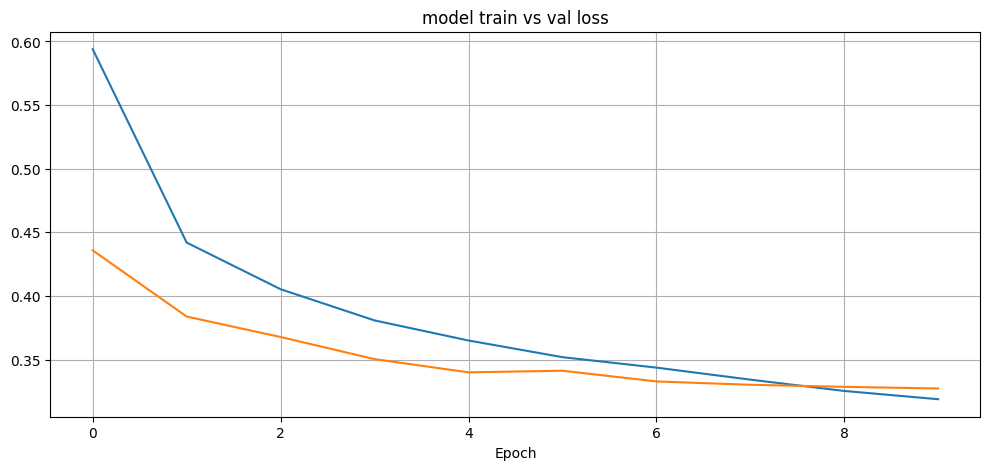

In [48]:

h_layer = keras.layers.Dense(units=100, activation="relu")
# 드롭아웃 전처리 계층 추가
# -0.3의 의미: 특성들 중에 30% 제외 시키겠다는 의미 (100개 중 넘기는건 70이지만 100으로 표시됨 30은 내부 비활성화)
d_layer = keras.layers.Dropout(0.3)

### 모델 생성 : 은닉계층 함수에 전달
model = model_fn([h_layer,d_layer])
model.summary()

### 모델 환경설정
#adam = keras.optimizers.Adam(learning_rate=0.1)
adam = keras.optimizers.Adam(learning_rate=0.001)
model.compile(
    optimizer=adam,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### 훈련시키기
history = model.fit(train_scaled_2, train_target, epochs=10,
                    validation_data=(val_scaled, val_target))

### 시각화
plt.title("model train vs val loss")
plt.plot(history.epoch, history.history["loss"])
plt.plot(history.epoch, history.history["val_loss"])
plt.grid()
plt.xlabel("Epoch")


### 모델 저장 및 복원하기 

In [ ]:
"""
<저장 방법>
 1. 최적의 모델이 훈련 중 사용한 "가중치만 저장"하는 방법
    - 훈련 중 손실을 줄이기 위해 모델이 스스로 찾아낸 가중치 값들
    - 읽어들이는 순서
       -- 모델 생성 > 저장된 가중치 읽어들여서 적용 > 예측 진행
          (훈련 fit은 별도로 하지 않습니다)
         
 2. 최적의 "모델 자체를 저장"하는 방법
    - 훈련 최종 결과물 모델 자체를 저장합니다.
    - 읽어들이는 순서
       -- 모델 읽어들이기 > 예측 진행
          (별도로 모델 생성 및 훈련을 하지 않아도 됩니다.)
"""

### 1. 최적의 모델이 훈련 중 사용한 "가중치만 저장"하는 방법

In [ ]:
### 모델 가중치만 저장
# - 파일 확장자: .weights.h5
# *** 파일로 저장한 가중치를 사용하는 곳 : 서비스를 수행하는 시스템에서 사용
model.save_weights("./models/model.weights.h5")

In [53]:
### 저장된 가중치 파일 불러들이기
# 사용 순서
# 1. 모델 생성하기 (가중치 저장시 사용한 모델 형태 그대로 생성)
# 2. 계층추가
# 3. 불러들인 가중치 주입(적용): load_weights()함수 사숑
# 4. 예측 진행(훈련 fit은 하지않음)
# *** 파일로 저장한 가중치를 사용하는 곳 : 서비스를 수행하는 시스템에서 사용

h_layer = keras.layers.Dense(units=100, activation="relu")
# 드롭아웃 전처리 계층 추가
# -0.3의 의미: 특성들 중에 30% 제외 시키겠다는 의미 (100개 중 넘기는건 70이지만 100으로 표시됨 30은 내부 비활성화)
d_layer = keras.layers.Dropout(0.3)

### 모델 생성 : 은닉계층 함수에 전달
model_w = model_fn([h_layer,d_layer])

### 생성된 모델에 가중치 주입(적용) 시키기
model_w.load_weights("./models/model.weights.h5")
model_w.summary()

### 이후 예측(predict) 진행

Model: "sequential_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_27 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

### 2. 최적의 "모델자체를 저장"하는 방법

In [ ]:
### 모델 자체 저장하기
## 확장자 - keras
model.save("./models/model_all.keras")

In [ ]:
### 저장된 모델 불러들이기
# - 별도로 모델을 생성할 필요가 없음
model_all = keras.models.load_model("./models/model_all.keras")
model_all.summary()


Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_25 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 238,532 (931.77 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 159,022 (621.18 KB)

### 테스트 데이터로 예측하기

In [57]:
### 가중치 모델로 예측하기
test_pred_w = model_w.predict(test_scaled_255)
test_pred_w

102/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

E0000 00:00:1793253720.342662   72640 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([[1.1369132e-08, 1.6702060e-12, 1.8874453e-10, ..., 1.5802712e-03,
        3.9507208e-07, 9.9384516e-01],
       [4.4289474e-05, 1.2087862e-13, 9.9033338e-01, ..., 1.4158908e-13,
        3.5616971e-08, 2.5097671e-14],
       [6.6929808e-09, 1.0000000e+00, 7.3084899e-11, ..., 1.7632940e-24,
        9.1892619e-17, 7.3175722e-18],
       ...,
       [2.4706451e-04, 1.0032268e-12, 2.5520737e-06, ..., 4.4991428e-09,
        9.9970299e-01, 1.4403374e-13],
       [6.2855663e-09, 9.9999225e-01, 9.7479058e-10, ..., 2.4379511e-17,
        1.4527703e-11, 7.5975936e-12],
       [1.1111577e-05, 3.3700207e-08, 5.7292264e-06, ..., 1.0293139e-03,
        1.4300928e-04, 4.7924870e-05]], shape=(10000, 10), dtype=float32)

In [68]:
### 모델 자체로 예측하기

test_pred_all = model_all.predict(test_scaled_255)
test_pred_all

123/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

E0000 00:00:1793254500.631243   72640 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([[1.1369132e-08, 1.6702060e-12, 1.8874453e-10, ..., 1.5802712e-03,
        3.9507208e-07, 9.9384516e-01],
       [4.4289474e-05, 1.2087862e-13, 9.9033338e-01, ..., 1.4158908e-13,
        3.5616971e-08, 2.5097671e-14],
       [6.6929808e-09, 1.0000000e+00, 7.3084899e-11, ..., 1.7632940e-24,
        9.1892619e-17, 7.3175722e-18],
       ...,
       [2.4706451e-04, 1.0032268e-12, 2.5520737e-06, ..., 4.4991428e-09,
        9.9970299e-01, 1.4403374e-13],
       [6.2855663e-09, 9.9999225e-01, 9.7479058e-10, ..., 2.4379511e-17,
        1.4527703e-11, 7.5975936e-12],
       [1.1111577e-05, 3.3700207e-08, 5.7292264e-06, ..., 1.0293139e-03,
        1.4300928e-04, 4.7924870e-05]], shape=(10000, 10), dtype=float32)

In [69]:
### 예측결과 차원 확인
test_pred_all.shape,test_pred_w.shape

((10000, 10), (10000, 10))

In [77]:
### 0번째 행의 예측결과 확인
# - 예측결과는 다중분류이므로, 10개 범주에 대한 확률값이 들어있음
#   -> 10개 중에 가장 큰 값을 가지는 위치의 "인덱스 번호가 범주 값"이 됨
print(test_pred_all[0])

### 가장 큰값을 가지고 있는 인덱스 위치(번호) 확인하기
print(np.argmax(test_pred_all[0]))

### 테스트 데이터의 0번째 행의 실제 종속변수(정답) 확인하기
print(test_target[0])

[1.1369132e-08 1.6702060e-12 1.8874453e-10 3.7872914e-09 2.0835222e-09
 4.5741489e-03 1.5974257e-08 1.5802712e-03 3.9507208e-07 9.9384516e-01]
9
9


In [95]:
"""
정답 갯수, 오답갯수, 정답률 ,오답률 직접 계산해서 출력해주세요
(함수사용 가능:np,argxmax,np.sum,len)
"""
### 제일 먼저 예측결과 2차원 데이터에서
#   -> 행마다 가장 각 열에 대한 큰값의 인덱스값을 추출하여 1차원으로 모으기(axis=1 추가)
test_pred_max = np.argmax(test_pred_all, axis=1)
print(test_pred_max,len(test_pred_max))


### 정답갯수
ok= np.sum(test_pred_max == test_target)
print(f"정답갯수 {ok}")
### 오답갯수
no= np.sum(test_pred_max != test_target)
print(f"오답갯수 {ok}")

### 정답률
ok_p=ok/len(test_target)
print(f"정답률:{ok_p}({ok_p*100:.3f})%")

### 오답률
no_p = no/len(test_target)
print(f"오답률:{no_p}({no_p * 100:.3f}%)")

[9 2 1 ... 8 1 5] 10000
정답갯수 8726
오답갯수 8726
정답률:0.8726(87.260)%
오답률:0.1274(12.740%)


### 훈련 중 최적화 시점에서 모델 저장시키기

In [ ]:
"""
<최적화 시점의 모델 저장>
 - 최적화 시점은 가장 일반화가 잘된 시점을 의미함
 - 훈련(fit) 반복 중에 가장 좋은 시점(손실이 적거나, 더 이상 손실이 낮아지지 않는 시점)에
   -> 모델을 저장해서 사용하는 방법을 의미함

<콜백(Callback) 함수>
 - 모델 훈련 중에 특정 작업(함수)을 호출(call)하여 수행하고자 할 때 사용
 - 훈련 시에 fit 함수에 적용하여 사용합니다.
 - 훈련 중에 발생시키는 함수라는 의미로 -> "이벤트(event) 함수"라고도 칭합니다.
 - 별도의 계층은 아니며, fit함수의 속성(매개변수)로 사용됩니다.

<콜백(Callback) 함수 종류>
 1. ModelCheckpoint() 함수 : 모델(model) 확인(check) 시점(point) 확인 함수
  - epoch 마다 모델을 저장하는 기능을 수행하는 함수
  - 단, 이전 epoch에서 실행된 훈련 성능보다 높아진 경우에만 저장됨
 
 2. EaralyStopping() 함수 : 조기(earaly) 종료(stopping) 함수
  - 훈련이 더 이상 좋아지지 않으면(loss 기준) 훈련을 종료시키는 함수
  - 일반적으로 ModelCheckpoint()와 함께 사용함
"""

### 사용할 모델 생성하기

### 1.ModelCheckpoint()콜백 함수 사용하기

In [98]:
### 훈련(fit) 시키기 전에 콜백 함수를 먼저 정의해야함
checkpoint_cb = keras.callbacks.ModelCheckpoint(
    ### 모델 저장 위치 지정
    "./models/best_model_01.keras",
 
 ## epoch마다 훈련모델을 자동 저장할지 여부 설정
    # save_best_only=True  : 모델 성능이 좋은 시점에만 저장
    # save_best_only=False : epoch마다 무조건 저장(처음건 무조건 저장) 
    save_best_only=True
)
checkpoint_cb

In [97]:
h_layer = keras.layers.Dense(units=100, activation="relu")
# 드롭아웃 전처리 계층 추가
# -0.3의 의미: 특성들 중에 30% 제외 시키겠다는 의미 (100개 중 넘기는건 70이지만 100으로 표시됨 30은 내부 비활성화)
d_layer = keras.layers.Dropout(0.3)

### 모델 생성 : 은닉계층 함수에 전달
model = model_fn([h_layer,d_layer])
model.summary()

### 모델 환경설정
#adam = keras.optimizers.Adam(learning_rate=0.1)
adam = keras.optimizers.Adam(learning_rate=0.001)
model.compile(
    optimizer=adam,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

/home/server/workspace/02_Deep_Learning_TensorFlow/.venv/lib/python3.10/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_28"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_28 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

### 2. EaralyStopping()  콜백 함수 사용하기

In [101]:
early_stopping_cb = keras.callbacks.EarlyStopping(
   
### 더 이상 좋아지지 않는 epoch의 갯수 지정
# - 가장 좋은 시점의 epoch 이후 n번 더 수행 후에
# - 그래도 좋아지지 않으면 종료 시키겠다는 의미로 사용됨
# - 주로 2 또는 3의 값을 사용
    patience=2,
    ### 종료 시점에 가장 낮은 검증 손실일 때의
    # -> 하이퍼파라메터로 모델을 업데이트 시킴 (가중치 업데이트)
    restore_best_weights=True
)

In [ ]:
### 콜백 함수를 이용하여 훈련시키기

#- 보통 ModelCheckpoiint와 EarlyStopping 콜백 함수는 주로 함께 사용됩니다.
history = model.fit(
    train_scaled_2, train_target, epochs=10000,

### 콜백함수를 사용하는 경우에는 검증 데이터를 무조건 넣어 주셔야 합니다.
# - 콜백함수가 성능이 좋다/안좋다를 판단하기 위해서
validation_data = (val_scaled, val_target),

### 콜백 함수 적용 속성
callbacks = [checkpoint_cb, early_stopping_cb]
)

Epoch 1/10000
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7920 - loss: 0.5887 - val_accuracy: 0.8407 - val_loss: 0.4298
Epoch 2/10000
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8416 - loss: 0.4385 - val_accuracy: 0.8583 - val_loss: 0.3843
Epoch 3/10000
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8530 - loss: 0.4004 - val_accuracy: 0.8637 - val_loss: 0.3719
Epoch 4/10000
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8634 - loss: 0.3781 - val_accuracy: 0.8717 - val_loss: 0.3489
Epoch 5/10000
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8671 - loss: 0.3655 - val_accuracy: 0.8741 - val_loss: 0.3410
Epoch 6/10000
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8704 - loss: 0.3490 - val_accuracy: 0.8778 - val_loss: 0.3342
Epoch 7/10000
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8755 - loss: 0.3398 - val_accuracy: 0.8782 - val_loss: 0.3343
Epoch 8/10000
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 

### 성능검증

In [110]:
### 콜백함수를 이용하여 훈련 중 저장된 모델을 불러들여서 이용해야함

# - 1. 저장된 최적의 모델 불러들이기

best_model = keras.models.load_model("./models/best_model_01.keras")
model_all.summary()

# 2. 훈련데이터로 성능 검증하기
train_score = best_model.evaluate(train_scaled_2, train_target)
train_loss = train_score[0]

# 3. 검증데이터로 성능 검증하기
val_score = best_model.evaluate(val_scaled, val_target)
val_loss = val_score[0]

# 4. 과적합 여부 확인하기(훈련 손실 - 검증 손실)
# - (훈련 손실 - 검증 손실)의 결과값이 음수(-)값이 나오면 과소적합은 아님
# - (훈련 손실 - 검증 손실)의 값이 -0.04706로 과대/과소 적합은 보이지 않음(일반화는 잘 되었음)
#   - 단, 훈련 정확도는 0.89로 매우 높다고 볼수는 없음
print(f"훈련-검증 손실 : {train_loss-val_loss:.5f}")

Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_25 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 238,532 (931.77 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 159,022 (621.18 KB)

1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8934 - loss: 0.2863
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8778 - loss: 0.3342
훈련-검증 손실 : -0.04792
